# CrediSmart: Parte 1: Rede Neural MLP implementada do zero
Neste bloco criamos a base de dados, a MLP (só com NumPy), o Perceptron de Rosenblatt
e comparamos com os modelos do scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

## 1. Base de dados (função e semente obrigatórias)

In [ ]:
def gerar_dados(n=2000, seed=2026):
    rng = np.random.default_rng(seed)
    renda = rng.lognormal(8.2, 0.5, n)
    idade = rng.integers(18, 71, n)
    comp = np.clip(rng.beta(2, 3, n), 0, 1)
    atrasos = rng.poisson(0.8, n)
    emprego = np.clip(rng.exponential(5, n), 0, 40)
    z = (-2.0 + 4.0 * comp**2 + 0.9 * atrasos - 0.35 * np.log(renda / 2000)
         - 0.06 * emprego + 0.0012 * (idade - 40)**2 + 1.5 * comp * (atrasos > 1)
         + rng.normal(0, 0.6, n))
    y = (z > 0).astype(int)
    X = np.column_stack([renda, idade, comp, atrasos, emprego]).astype(float)
    return X, y

X, y = gerar_dados()
print("Formato de X:", X.shape, "| proporção de inadimplentes:", y.mean().round(3))

Formato de X: (2000, 5) | proporção de inadimplentes: 0.303


## 2. Divisão treino/validação/teste e padronização
- Embaralhamos com `default_rng(42).permutation`.
- 1400 treino, 300 validação e 300 teste.
- Aplicamos log na renda e depois o z-score. **Média e desvio vêm só do treino**,
  para não haver vazamento de dados (data leakage).

In [ ]:
perm = np.random.default_rng(42).permutation(len(X))
X, y = X[perm], y[perm]

X_tr, y_tr = X[:1400], y[:1400]
X_va, y_va = X[1400:1700], y[1400:1700]
X_te, y_te = X[1700:], y[1700:]

def aplicar_log_renda(A):
    A = A.copy()
    A[:, 0] = np.log(A[:, 0])   # coluna 0 = renda
    return A

X_tr, X_va, X_te = aplicar_log_renda(X_tr), aplicar_log_renda(X_va), aplicar_log_renda(X_te)

media = X_tr.mean(axis=0)       # calculada SÓ no treino
desvio = X_tr.std(axis=0)
Xs_tr = (X_tr - media) / desvio
Xs_va = (X_va - media) / desvio
Xs_te = (X_te - media) / desvio
print("Treino:", Xs_tr.shape, "Validação:", Xs_va.shape, "Teste:", Xs_te.shape)

Treino: (1400, 5) Validação: (300, 5) Teste: (300, 5)


## 3. A classe MLP (uma camada oculta, só NumPy)

Arquitetura: entrada → camada oculta (tanh) → saída (sigmoide).

- **Forward:** `Z1 = X·W1 + b1`, `A1 = tanh(Z1)`, `Z2 = A1·W2 + b2`, `p = sigmoide(Z2)`
- **Perda:** entropia cruzada binária `L = -média[ y·log(p) + (1-y)·log(1-p) ]`
- **Backpropagation:** com sigmoide + entropia cruzada, o gradiente na saída é simplesmente `dZ2 = p - y`.
  Depois propagamos para trás: `dW2 = A1ᵀ·dZ2`, `dA1 = dZ2·W2ᵀ`, `dZ1 = dA1 · (1 - A1²)`, `dW1 = Xᵀ·dZ1`.
- **Gradiente descendente:** `W ← W - taxa · dW`.

In [4]:
def sigmoide(z):
    z = np.clip(z, -500, 500)            # evita overflow
    return 1.0 / (1.0 + np.exp(-z))

class MLP:
    def __init__(self, n_entrada, n_ocultos, taxa=0.1, epocas=1000, seed=0):
        self.taxa = taxa
        self.epocas = epocas
        rng = np.random.default_rng(seed)
        # Inicialização de Xavier: pesos pequenos, escalados pelo tamanho da camada
        self.W1 = rng.normal(0, np.sqrt(1.0 / n_entrada), (n_entrada, n_ocultos))
        self.b1 = np.zeros(n_ocultos)
        self.W2 = rng.normal(0, np.sqrt(1.0 / n_ocultos), (n_ocultos, 1))
        self.b2 = np.zeros(1)
        self.historico = []              # perda por época

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = np.tanh(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        return sigmoide(self.Z2).ravel()

    def perda(self, y, p):
        p = np.clip(p, 1e-12, 1 - 1e-12)   # evita log(0)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def backward(self, X, y, p):
        n = len(y)
        dZ2 = (p - y).reshape(-1, 1)                  # (n, 1)
        dW2 = self.A1.T @ dZ2 / n
        db2 = dZ2.mean(axis=0)
        dA1 = dZ2 @ self.W2.T                         # (n, ocultos)
        dZ1 = dA1 * (1 - self.A1**2)                  # derivada da tanh
        dW1 = X.T @ dZ1 / n
        db1 = dZ1.mean(axis=0)
        # passo do gradiente descendente
        self.W2 -= self.taxa * dW2
        self.b2 -= self.taxa * db2
        self.W1 -= self.taxa * dW1
        self.b1 -= self.taxa * db1

    def fit(self, X, y):
        self.historico = []
        for _ in range(self.epocas):
            p = self.forward(X)
            self.historico.append(self.perda(y, p))
            self.backward(X, y, p)
        return self

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X, limiar=0.5):
        return (self.predict_proba(X) >= limiar).astype(int)

### Conferência do backpropagation (gradient check)
Comparamos o gradiente calculado pela fórmula com uma aproximação numérica.
Se a diferença for minúscula, o backpropagation está correto.

In [5]:
rng = np.random.default_rng(1)
Xt, yt = rng.normal(size=(20, 3)), rng.integers(0, 2, 20)
rede = MLP(3, 4, taxa=0.0)             # taxa 0: não altera os pesos
p = rede.forward(Xt)
W1_antes = rede.W1.copy()

# gradiente analítico de W1 (mesma fórmula do backward)
dZ2 = (p - yt).reshape(-1, 1)
dZ1 = (dZ2 @ rede.W2.T) * (1 - rede.A1**2)
grad_analitico = Xt.T @ dZ1 / len(yt)

# gradiente numérico (diferenças finitas)
grad_num = np.zeros_like(rede.W1)
h = 1e-5
for i in range(rede.W1.shape[0]):
    for j in range(rede.W1.shape[1]):
        rede.W1[i, j] = W1_antes[i, j] + h
        l_mais = rede.perda(yt, rede.forward(Xt))
        rede.W1[i, j] = W1_antes[i, j] - h
        l_menos = rede.perda(yt, rede.forward(Xt))
        rede.W1[i, j] = W1_antes[i, j]
        grad_num[i, j] = (l_mais - l_menos) / (2 * h)

print("Maior diferença entre gradiente analítico e numérico:",
      np.abs(grad_analitico - grad_num).max())

Maior diferença entre gradiente analítico e numérico: 2.6622225257622034e-11


## 4. Validação no XOR
O XOR não é linearmente separável. Treinamos o Perceptron e a MLP no mesmo problema.

Alvo:                 [0 1 1 0]
Perceptron previu:    [1 0 0 0] -> acertos: 1 / 4
MLP previu:           [0 1 1 0] -> acertos: 4 / 4
Probabilidades MLP:   [0.    0.999 0.999 0.001]


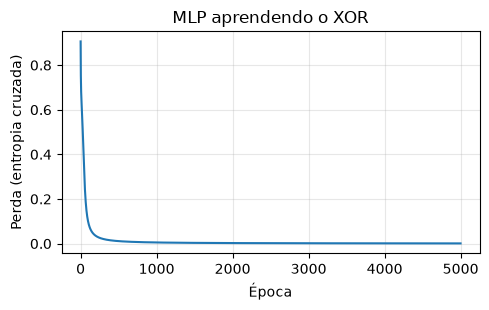

In [6]:
class Perceptron:
    """Perceptron de Rosenblatt: saída em degrau e regra w ← w + taxa·(y - ŷ)·x"""
    def __init__(self, n_entrada, taxa=0.1, epocas=100, seed=0):
        rng = np.random.default_rng(seed)
        self.w = rng.normal(0, 0.1, n_entrada)
        self.b = 0.0
        self.taxa = taxa
        self.epocas = epocas

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

    def fit(self, X, y):
        for _ in range(self.epocas):
            for xi, yi in zip(X, y):
                erro = yi - int(xi @ self.w + self.b >= 0)
                self.w += self.taxa * erro * xi
                self.b += self.taxa * erro
        return self

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

perc = Perceptron(2, taxa=0.1, epocas=200).fit(X_xor, y_xor)
mlp_xor = MLP(2, 4, taxa=0.5, epocas=5000, seed=3).fit(X_xor, y_xor)

print("Alvo:                ", y_xor)
print("Perceptron previu:   ", perc.predict(X_xor), "-> acertos:", (perc.predict(X_xor) == y_xor).sum(), "/ 4")
print("MLP previu:          ", mlp_xor.predict(X_xor), "-> acertos:", (mlp_xor.predict(X_xor) == y_xor).sum(), "/ 4")
print("Probabilidades MLP:  ", mlp_xor.predict_proba(X_xor).round(3))

plt.figure(figsize=(5, 3.2))
plt.plot(mlp_xor.historico)
plt.xlabel("Época"); plt.ylabel("Perda (entropia cruzada)")
plt.title("MLP aprendendo o XOR"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_xor_perda.png", dpi=150); plt.show()

**Por que o Perceptron não resolve o XOR?**
O Perceptron separa as classes com uma única reta (hiperplano): `w·x + b = 0`. No XOR, os pontos
(0,0) e (1,1) são da classe 0 e (0,1) e (1,0) são da classe 1; nenhuma reta consegue deixar
as duas classes cada uma de um lado, ou seja, o problema **não é linearmente separável**.
A MLP resolve porque a camada oculta com função não linear (tanh) transforma os pontos para um
novo espaço onde eles passam a ser separáveis, e a camada de saída então os separa com uma reta.
Em outras palavras, a rede combina várias fronteiras lineares em uma fronteira não linear.

## 5. Treino da MLP na base de crédito
Configuração **manual** (será comparada depois com a do Algoritmo Genético):
8 neurônios ocultos, taxa de aprendizado 0,1 e 1000 épocas.

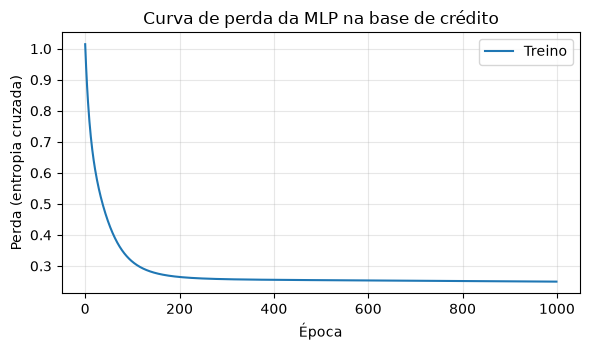

Perda final no treino: 0.2495


In [7]:
def metricas(y_real, y_prev):
    vp = np.sum((y_real == 1) & (y_prev == 1))
    vn = np.sum((y_real == 0) & (y_prev == 0))
    fp = np.sum((y_real == 0) & (y_prev == 1))
    fn = np.sum((y_real == 1) & (y_prev == 0))
    acc = (vp + vn) / len(y_real)
    prec = vp / (vp + fp) if (vp + fp) > 0 else 0.0
    rec = vp / (vp + fn) if (vp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return {"Acurácia": acc, "Precisão": prec, "Recall": rec, "F1": f1}

CONFIG_MANUAL = {"n_ocultos": 8, "taxa": 0.1, "epocas": 1000}

mlp = MLP(5, CONFIG_MANUAL["n_ocultos"], CONFIG_MANUAL["taxa"], CONFIG_MANUAL["epocas"], seed=0)
mlp.fit(Xs_tr, y_tr)

plt.figure(figsize=(6, 3.6))
plt.plot(mlp.historico, label="Treino")
plt.xlabel("Época"); plt.ylabel("Perda (entropia cruzada)")
plt.title("Curva de perda da MLP na base de crédito")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("fig_curva_perda.png", dpi=150); plt.show()
print("Perda final no treino:", round(mlp.historico[-1], 4))

## 6. Comparativo no conjunto de teste (4 modelos)

In [ ]:
perc_cred = Perceptron(5, taxa=0.01, epocas=100).fit(Xs_tr, y_tr)
reglog = LogisticRegression(max_iter=1000).fit(Xs_tr, y_tr)
mlp_sk = MLPClassifier(hidden_layer_sizes=(8,), learning_rate_init=0.1, max_iter=1000,
                       random_state=0).fit(Xs_tr, y_tr)

modelos = {
    "Perceptron (Rosenblatt)": perc_cred.predict(Xs_te),
    "Regressão Logística (sklearn)": reglog.predict(Xs_te),
    "MLPClassifier (sklearn)": mlp_sk.predict(Xs_te),
    "Nossa MLP": mlp.predict(Xs_te),
}

print(f"{'Modelo':32s} {'Acurácia':>9s} {'Precisão':>9s} {'Recall':>9s} {'F1':>9s}")
tabela = {}
for nome, pred in modelos.items():
    m = metricas(y_te, pred)
    tabela[nome] = m
    print(f"{nome:32s} {m['Acurácia']:9.3f} {m['Precisão']:9.3f} {m['Recall']:9.3f} {m['F1']:9.3f}")

## 7. Limiar de decisão e custo dos erros
- **Falso positivo (FP):** classificar como inadimplente quem pagaria → a fintech deixa de ganhar
  juros e perde um cliente.
- **Falso negativo (FN):** aprovar crédito a quem não vai pagar → perde-se o valor emprestado.

Em crédito, o FN costuma custar bem mais que o FP. Vamos supor, como exemplo, **FN = 5 × FP**.
Escolhemos o limiar que minimiza o custo **na validação** (nunca no teste) e só depois o aplicamos ao teste.

In [ ]:
CUSTO_FP, CUSTO_FN = 1, 5
limiares = np.linspace(0.05, 0.95, 91)
p_va = mlp.predict_proba(Xs_va)

def custo_total(y_real, p, lim):
    pred = (p >= lim).astype(int)
    fp = np.sum((y_real == 0) & (pred == 1))
    fn = np.sum((y_real == 1) & (pred == 0))
    return CUSTO_FP * fp + CUSTO_FN * fn

custos_va = [custo_total(y_va, p_va, t) for t in limiares]
limiar_otimo = limiares[int(np.argmin(custos_va))]

plt.figure(figsize=(6, 3.6))
plt.plot(limiares, custos_va)
plt.axvline(0.5, color="gray", linestyle="--", label="Limiar 0,5")
plt.axvline(limiar_otimo, color="red", linestyle="--", label=f"Limiar ótimo = {limiar_otimo:.2f}")
plt.xlabel("Limiar de decisão"); plt.ylabel("Custo total (validação)")
plt.title("Custo × limiar (FN custa 5× o FP)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_limiar.png", dpi=150); plt.show()

p_te = mlp.predict_proba(Xs_te)
for lim in (0.5, limiar_otimo):
    m = metricas(y_te, (p_te >= lim).astype(int))
    print(f"Limiar {lim:.2f} no teste -> custo = {custo_total(y_te, p_te, lim)}, "
          f"recall = {m['Recall']:.3f}, precisão = {m['Precisão']:.3f}, F1 = {m['F1']:.3f}")

# CrediSmart: Parte 2: Controlador Fuzzy Mamdani (do zero)
Entradas: probabilidade de inadimplência (0 a 1) e comprometimento de renda (0 a 1).
Saída: limite de crédito recomendado, em % do limite máximo (0 a 100).

In [8]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Funções de pertinência
Usamos uma única função trapezoidal `trap(x, a, b, c, d)`.
O triângulo é o caso particular em que `b = c`.
- Sobe de 0 a 1 entre `a` e `b`, fica em 1 entre `b` e `c`, desce até 0 entre `c` e `d`.

In [ ]:
def trap(x, a, b, c, d):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    if b > a:
        sobe = (x > a) & (x < b)
        y[sobe] = (x[sobe] - a) / (b - a)
    plano = (x >= b) & (x <= c)
    y[plano] = 1.0
    if d > c:
        desce = (x > c) & (x < d)
        y[desce] = (d - x[desce]) / (d - c)
    return y

# Parâmetros (a, b, c, d) de cada termo
# Entradas: ombros nas pontas (Baixo e Alto) e um triângulo no meio.
# Os termos se sobrepõem para que a transição entre eles seja gradual.
ENTRADA = {
    "Baixo": (0.0, 0.0, 0.15, 0.40),
    "Médio": (0.20, 0.45, 0.45, 0.70),
    "Alto":  (0.50, 0.75, 1.00, 1.00),
}
# Saída (limite de crédito em % do máximo)
SAIDA = {
    "Baixo": (0, 0, 15, 40),
    "Médio": (25, 50, 50, 75),
    "Alto":  (60, 85, 100, 100),
}

**Justificativa das funções de pertinência**
- Probabilidade de inadimplência: até ~15% o risco é claramente baixo; em torno de 45% é médio;
  acima de ~75% é claramente alto. Entre esses pontos há sobreposição, porque "risco médio"
  não tem fronteira exata.
- Comprometimento de renda: usamos os mesmos formatos, já que na base ele varia de 0 a 1 e
  comprometer mais de ~75% da renda já é considerado alto.
- Saída: o limite é dividido em três faixas (baixo, médio, alto) com centros em ~8%, 50% e ~92%,
  deixando espaço para o centroide gerar valores intermediários.

In [ ]:
x01 = np.linspace(0, 1, 501)
x100 = np.linspace(0, 100, 1001)

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (titulo, universo, termos, xlabel) in zip(eixos, [
    ("Entrada 1: Probabilidade de inadimplência", x01, ENTRADA, "Probabilidade"),
    ("Entrada 2: Comprometimento de renda", x01, ENTRADA, "Comprometimento"),
    ("Saída: Limite de crédito", x100, SAIDA, "% do limite máximo"),
]):
    for nome, par in termos.items():
        ax.plot(universo, trap(universo, *par), label=nome, linewidth=2)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel)
    ax.set_ylabel("Pertinência"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("fig_pertinencia.png", dpi=150); plt.show()

## 2. Base de regras (9 regras)
Formato: SE probabilidade é X E comprometimento é Y ENTÃO limite é Z.

| # | Probabilidade | Comprometimento | Limite | Justificativa |
|---|---|---|---|---|
| 1 | Baixo | Baixo | Alto | Bom pagador com renda folgada: pode receber limite alto. |
| 2 | Baixo | Médio | Alto | Risco baixo compensa um comprometimento moderado. |
| 3 | Baixo | Alto | Médio | Bom histórico, mas a renda já está apertada: limite moderado. |
| 4 | Médio | Baixo | Médio | Risco intermediário, mas com folga de renda. |
| 5 | Médio | Médio | Médio | Situação intermediária em tudo. |
| 6 | Médio | Alto | Baixo | Risco médio e renda apertada: limite pequeno. |
| 7 | Alto | Baixo | Baixo | Risco alto: mesmo com renda folgada, o limite é cauteloso. |
| 8 | Alto | Médio | Baixo | Risco alto pesa mais que o comprometimento. |
| 9 | Alto | Alto | Baixo | Pior cenário: limite mínimo. |

In [ ]:
# (termo da probabilidade, termo do comprometimento, termo do limite)
REGRAS = [
    ("Baixo", "Baixo", "Alto"),
    ("Baixo", "Médio", "Alto"),
    ("Baixo", "Alto",  "Médio"),
    ("Médio", "Baixo", "Médio"),
    ("Médio", "Médio", "Médio"),
    ("Médio", "Alto",  "Baixo"),
    ("Alto",  "Baixo", "Baixo"),
    ("Alto",  "Médio", "Baixo"),
    ("Alto",  "Alto",  "Baixo"),
]

## 3. Motor de inferência Mamdani
1. **Fuzzificação:** calcula a pertinência de cada entrada em Baixo/Médio/Alto.
2. **Ativação das regras:** AND = **mínimo** entre as duas pertinências.
3. **Implicação:** corta (com `min`) o termo de saída na altura da ativação da regra.
4. **Agregação:** une os recortes com o **máximo**.
5. **Defuzzificação:** **centroide** = Σ(y · μ(y)) / Σ μ(y).

In [ ]:
def inferir(prob, comp, detalhe=False):
    # 1) Fuzzificação
    mu_p = {t: float(trap(np.array([prob]), *par)[0]) for t, par in ENTRADA.items()}
    mu_c = {t: float(trap(np.array([comp]), *par)[0]) for t, par in ENTRADA.items()}

    # 2) e 3) Ativação e implicação
    ativacoes, recortes = [], []
    for tp, tc, ts in REGRAS:
        forca = min(mu_p[tp], mu_c[tc])                         # AND = mínimo
        ativacoes.append(forca)
        recortes.append(np.minimum(forca, trap(x100, *SAIDA[ts])))

    # 4) Agregação (máximo)
    agregada = np.max(recortes, axis=0)

    # 5) Centroide
    area = agregada.sum()
    limite = (x100 * agregada).sum() / area if area > 0 else 50.0

    if detalhe:
        return limite, dict(mu_p=mu_p, mu_c=mu_c, ativacoes=ativacoes,
                            recortes=recortes, agregada=agregada)
    return limite

## 4. Exemplo passo a passo
Cliente de exemplo: probabilidade de inadimplência = 0,35 e comprometimento de renda = 0,35.
(No pipeline final usaremos clientes reais do teste.)

In [ ]:
PROB, COMP = 0.35, 0.35
limite, d = inferir(PROB, COMP, detalhe=True)

print(f"CLIENTE: probabilidade = {PROB}, comprometimento = {COMP}\n")
print("PASSO 1: Fuzzificação")
for t in ENTRADA:
    print(f"  Probabilidade é {t:5s}: μ = {d['mu_p'][t]:.3f}      "
          f"Comprometimento é {t:5s}: μ = {d['mu_c'][t]:.3f}")

print("\nPASSO 2: Ativação das regras (AND = mínimo)")
for i, ((tp, tc, ts), f) in enumerate(zip(REGRAS, d["ativacoes"]), start=1):
    marca = "  <- ativa" if f > 0 else ""
    print(f"  R{i}: SE prob={tp:5s} E comp={tc:5s} ENTÃO limite={ts:5s} | "
          f"min({d['mu_p'][tp]:.3f}, {d['mu_c'][tc]:.3f}) = {f:.3f}{marca}")

print("\nPASSO 3: Agregação (máximo dos recortes), por termo de saída")
for t in SAIDA:
    fs = [f for (tp, tc, ts), f in zip(REGRAS, d["ativacoes"]) if ts == t]
    print(f"  Limite {t:5s}: altura = máx{[round(f, 3) for f in fs]} = {max(fs):.3f}")

print("\nPASSO 4: Centroide")
num = (x100 * d["agregada"]).sum(); den = d["agregada"].sum()
print(f"  Σ y·μ(y) = {num:.2f} | Σ μ(y) = {den:.2f} | limite = {num/den:.2f}% do máximo")

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
for (tp, tc, ts), f, rec in zip(REGRAS, d["ativacoes"], d["recortes"]):
    if f > 0:
        eixos[0].fill_between(x100, rec, alpha=0.35, label=f"{tp}/{tc} → {ts} ({f:.2f})")
eixos[0].set_title("Recortes das regras ativadas"); eixos[0].legend(fontsize=7)
eixos[1].fill_between(x100, d["agregada"], alpha=0.4, color="tab:blue")
eixos[1].axvline(limite, color="red", linestyle="--", label=f"Centroide = {limite:.1f}%")
eixos[1].set_title("Área agregada e defuzzificação"); eixos[1].legend()
for ax in eixos:
    ax.set_xlabel("Limite (% do máximo)"); ax.set_ylabel("Pertinência"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_passo_a_passo.png", dpi=150); plt.show()

## 5. Superfície de controle
Varremos as duas entradas em uma grade e calculamos o limite de saída em cada ponto.

In [ ]:
grade = np.linspace(0, 1, 41)
SUP = np.array([[inferir(p, c) for p in grade] for c in grade])   # linhas: comp, colunas: prob

fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(1, 2, 1)
im = ax1.imshow(SUP, origin="lower", extent=[0, 1, 0, 1], aspect="auto", cmap="viridis")
ax1.set_xlabel("Probabilidade de inadimplência"); ax1.set_ylabel("Comprometimento de renda")
ax1.set_title("Mapa de calor do limite recomendado (%)")
fig.colorbar(im, ax=ax1)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
P, C = np.meshgrid(grade, grade)
ax2.plot_surface(P, C, SUP, cmap="viridis")
ax2.set_xlabel("Prob. inadimplência"); ax2.set_ylabel("Comprometimento")
ax2.set_zlabel("Limite (%)"); ax2.set_title("Superfície de controle")
plt.tight_layout(); plt.savefig("fig_superficie.png", dpi=150); plt.show()

print("Limite mínimo na superfície: %.1f%% | máximo: %.1f%%" % (SUP.min(), SUP.max()))
print("Prob=0.05, comp=0.10 ->", round(inferir(0.05, 0.10), 1), "%")
print("Prob=0.90, comp=0.90 ->", round(inferir(0.90, 0.90), 1), "%")

**Interpretação da superfície**
- O limite cai conforme a probabilidade de inadimplência sobe: é o eixo que mais pesa na decisão
  (de ~82% com prob. 0 até ~18% com prob. 1, com comprometimento fixo em 0,3).
- O comprometimento de renda só faz diferença quando o risco é baixo: com prob. 0,1 o limite vai de
  ~85% (renda folgada) a 50% (renda muito comprometida). Com risco alto, o limite fica perto do
  mínimo (~15%) qualquer que seja o comprometimento, como definimos nas regras 7 a 9.
- A transição entre as regiões é gradual porque as funções de pertinência se sobrepõem. Os pequenos
  "degraus" que aparecem são típicos do Mamdani com mínimo/máximo: o resultado é linear por partes,
  e o centroide muda de inclinação quando uma regra passa a dominar outra.
- Há regiões planas nos extremos, porque ali só uma regra domina. Os valores extremos são ~15% e ~85%,
  e não 0% e 100%, porque o centroide faz uma média ponderada da área do termo de saída.

# CrediSmart: Parte 3: Algoritmo Genético para ajustar os hiperparâmetros da MLP
O AG é implementado do zero (sem DEAP). Ele usa a classe `MLP`, os dados e a função `metricas`
da Parte 1.

## 1. Projeto do AG

**Codificação do cromossomo:** vetor de 3 genes reais, `[neurônios, log10(taxa), épocas]`.
- Neurônios ocultos: de 2 a 32 (arredondado para inteiro).
- Taxa de aprendizado: de 10^-2,5 ≈ 0,003 a 10^0 = 1. Usamos o **logaritmo** da taxa porque
  ela varia em ordens de grandeza; assim o AG explora 0,01 e 0,1 com a mesma facilidade.
- Épocas: de 100 a 1500 (arredondado para inteiro).

**Função de aptidão:** F1 no conjunto de **validação**, com a MLP treinada só no treino.
O teste nunca é usado dentro do AG. Escolhemos o F1 porque a classe inadimplente é minoritária (~30%)
e a acurácia esconderia erros nela.

**Seleção:** torneio de tamanho 3 (sorteia 3 indivíduos e escolhe o melhor). É simples e mantém
pressão seletiva sem que o melhor domine a população cedo demais.

**Crossover:** aritmético, com probabilidade 0,8. O filho é `α·pai1 + (1-α)·pai2`, com α sorteado
em [0,1] para cada gene. Funciona bem com genes reais.

**Mutação:** gaussiana, probabilidade 0,25 por gene e desvio de 10% da faixa do gene. Mantém a diversidade
e permite refinar valores perto de uma boa solução. O valor é recortado para ficar dentro dos limites.

**Elitismo:** os 2 melhores indivíduos passam direto para a próxima geração, então a melhor aptidão
nunca piora.

In [ ]:
LIMITES = np.array([[2, 32],        # neurônios ocultos
                    [-2.5, 0.0],    # log10 da taxa de aprendizado
                    [100, 1500]])   # épocas

def decodificar(crom):
    n_ocultos = int(round(crom[0]))
    taxa = float(10 ** crom[1])
    epocas = int(round(crom[2]))
    return n_ocultos, taxa, epocas

_cache = {}   # evita retreinar o mesmo indivíduo mais de uma vez

def aptidao(crom):
    n_ocultos, taxa, epocas = decodificar(crom)
    chave = (n_ocultos, round(taxa, 5), epocas)
    if chave not in _cache:
        rede = MLP(5, n_ocultos, taxa, epocas, seed=0).fit(Xs_tr, y_tr)
        _cache[chave] = metricas(y_va, rede.predict(Xs_va))["F1"]   # F1 na VALIDAÇÃO
    return _cache[chave]

In [ ]:
def populacao_inicial(tamanho, rng):
    return rng.uniform(LIMITES[:, 0], LIMITES[:, 1], size=(tamanho, 3))

def torneio(pop, apt, rng, k=3):
    candidatos = rng.integers(0, len(pop), k)
    return pop[candidatos[np.argmax(apt[candidatos])]].copy()

def crossover(pai1, pai2, rng, prob=0.8):
    if rng.random() > prob:
        return pai1.copy()
    alfa = rng.random(3)
    return alfa * pai1 + (1 - alfa) * pai2

def mutacao(crom, rng, prob=0.25, escala=0.10):
    faixa = LIMITES[:, 1] - LIMITES[:, 0]
    for g in range(3):
        if rng.random() < prob:
            crom[g] += rng.normal(0, escala * faixa[g])
    return np.clip(crom, LIMITES[:, 0], LIMITES[:, 1])

def algoritmo_genetico(tam_pop=20, geracoes=15, n_elite=2, seed=7):
    rng = np.random.default_rng(seed)
    pop = populacao_inicial(tam_pop, rng)
    melhor_hist, media_hist = [], []
    for g in range(geracoes):
        apt = np.array([aptidao(c) for c in pop])
        melhor_hist.append(apt.max())
        media_hist.append(apt.mean())
        print(f"Geração {g+1:2d} | melhor F1 = {apt.max():.4f} | média = {apt.mean():.4f} "
              f"| melhor = {decodificar(pop[np.argmax(apt)])}")
        # nova geração: elite + filhos
        ordem = np.argsort(apt)[::-1]
        nova = [pop[i].copy() for i in ordem[:n_elite]]
        while len(nova) < tam_pop:
            filho = crossover(torneio(pop, apt, rng), torneio(pop, apt, rng), rng)
            nova.append(mutacao(filho, rng))
        pop = np.array(nova)
    apt = np.array([aptidao(c) for c in pop])     # avaliação final
    melhor_hist.append(apt.max()); media_hist.append(apt.mean())
    return pop[np.argmax(apt)], melhor_hist, media_hist

## 2. Execução (população de 20 indivíduos, 15 gerações)

In [ ]:
melhor_crom, melhor_hist, media_hist = algoritmo_genetico(tam_pop=20, geracoes=15)
n_opt, taxa_opt, ep_opt = decodificar(melhor_crom)
print(f"\nMelhor indivíduo: {n_opt} neurônios, taxa = {taxa_opt:.4f}, {ep_opt} épocas "
      f"(F1 validação = {melhor_hist[-1]:.4f})")
print("Avaliações distintas de MLP treinadas:", len(_cache))

plt.figure(figsize=(6.5, 3.8))
plt.plot(range(1, len(melhor_hist) + 1), melhor_hist, marker="o", label="Melhor aptidão")
plt.plot(range(1, len(media_hist) + 1), media_hist, marker="s", label="Aptidão média")
plt.xlabel("Geração"); plt.ylabel("F1 na validação")
plt.title("Convergência do Algoritmo Genético")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("fig_convergencia_ag.png", dpi=150); plt.show()

## 3. Comparação com a configuração manual (avaliação no TESTE)
Para uma comparação mais justa, treinamos cada configuração com 5 inicializações aleatórias
diferentes e olhamos a média e o desvio do F1. Assim vemos se a diferença é maior que o "ruído"
da inicialização dos pesos.

In [ ]:
CONFIG_AG = {"n_ocultos": n_opt, "taxa": taxa_opt, "epocas": ep_opt}

def avaliar_config(cfg, sementes=range(5)):
    f1_va, f1_te, rec_te, prec_te = [], [], [], []
    for s in sementes:
        rede = MLP(5, cfg["n_ocultos"], cfg["taxa"], cfg["epocas"], seed=s).fit(Xs_tr, y_tr)
        f1_va.append(metricas(y_va, rede.predict(Xs_va))["F1"])
        m = metricas(y_te, rede.predict(Xs_te))
        f1_te.append(m["F1"]); rec_te.append(m["Recall"]); prec_te.append(m["Precisão"])
    return np.array(f1_va), np.array(f1_te), np.array(rec_te), np.array(prec_te)

print(f"{'Configuração':10s} {'Neur.':>5s} {'Taxa':>7s} {'Épocas':>6s} | {'F1 valid.':>15s} | "
      f"{'F1 teste':>15s} | {'Recall':>6s} {'Precisão':>8s}")
for nome, cfg in [("Manual", CONFIG_MANUAL), ("AG", CONFIG_AG)]:
    fv, ft, rc, pr = avaliar_config(cfg)
    print(f"{nome:10s} {cfg['n_ocultos']:5d} {cfg['taxa']:7.4f} {cfg['epocas']:6d} | "
          f"{fv.mean():.3f} ± {fv.std():.3f}   | {ft.mean():.3f} ± {ft.std():.3f}   | "
          f"{rc.mean():.3f}  {pr.mean():.3f}")

## 4. Discussão: ganho real ou sobreajuste à validação?
O AG escolhe a configuração com o maior F1 na **validação**, então a validação fica "otimista"
para ele: o valor foi escolhido como o melhor entre centenas de tentativas. O que importa é o teste.
- Se o F1 de teste do AG for parecido com o da configuração manual (diferença dentro do desvio
  entre inicializações), o ganho de validação é em grande parte sobreajuste/ruído.
- Se o F1 de teste também melhora de forma consistente, o ganho é real.

**Leitura dos resultados desta execução (média de 5 inicializações):**
- **Sobreajuste à validação existe, mas é pequeno.** O F1 de validação da melhor execução do AG
  foi 0,862 (semente 0), mas a média nas 5 sementes é 0,838. Essa diferença de ~0,024 é o
  "otimismo" de escolher o melhor entre ~250 configurações testadas na mesma validação.
- **O ganho no teste é real.** O F1 de teste sobe de 0,816 (manual) para 0,854 (AG), uma diferença
  de ~0,04, bem maior que o desvio entre inicializações (~0,005). Recall e precisão também melhoram.
- **Por quê?** O AG encontrou uma taxa de aprendizado bem maior (~0,57, contra 0,1 da configuração
  manual). Com taxa 0,1 e 1000 épocas, a rede manual ainda estava "subtreinada"; com a taxa maior,
  converge melhor no mesmo número de épocas.
- **Limitação:** o teste tem só 300 amostras, então diferenças de 1 ou 2 pontos de F1 podem ser ruído.
  Por isso usamos várias inicializações; o ideal seria também validação cruzada.

# CrediSmart: Parte 4, pipeline completo
Fluxo: dados do cliente → MLP otimizada pelo AG → probabilidade de inadimplência →
controlador fuzzy (junto com o comprometimento de renda) → limite de crédito recomendado.

In [ ]:
# MLP final com a configuração encontrada pelo Algoritmo Genético
mlp_final = MLP(5, CONFIG_AG["n_ocultos"], CONFIG_AG["taxa"], CONFIG_AG["epocas"], seed=0)
mlp_final.fit(Xs_tr, y_tr)
print("Configuração usada:", CONFIG_AG)
print("Métricas da MLP otimizada no teste:",
      {k: round(float(v), 3) for k, v in metricas(y_te, mlp_final.predict(Xs_te)).items()})

def decidir_cliente(x_padronizado, comprometimento):
    """Recebe o cliente já padronizado e devolve (probabilidade, limite em %)."""
    prob = float(mlp_final.predict_proba(x_padronizado.reshape(1, -1))[0])
    limite = float(inferir(prob, comprometimento))
    return prob, limite

## Clientes do conjunto de teste
Pegamos 8 clientes do teste, espalhados do menor ao maior risco previsto, para mostrar como o
limite muda. Os dados originais (renda em R$, idade, etc.) são recuperados antes da padronização.

In [ ]:
probs_te = mlp_final.predict_proba(Xs_te)
ordem = np.argsort(probs_te)
indices = ordem[np.linspace(10, len(ordem) - 10, 8).astype(int)]   # 8 clientes espalhados

print(f"{'Cliente':>7s} {'Renda (R$)':>11s} {'Idade':>5s} {'Compr.':>6s} {'Atrasos':>7s} "
      f"{'Emprego':>7s} | {'Prob. inad.':>11s} {'Limite (%)':>10s} | {'Real':>12s}")
linhas = []
for i in indices:
    renda_real = float(np.exp(X_te[i, 0]))          # desfaz o log da renda
    idade, comp, atrasos, emprego = X_te[i, 1], X_te[i, 2], int(X_te[i, 3]), X_te[i, 4]
    prob, limite = decidir_cliente(Xs_te[i], comp)
    real = "inadimplente" if y_te[i] == 1 else "adimplente"
    linhas.append((int(i), renda_real, idade, comp, atrasos, emprego, prob, limite, real))
    print(f"{i:7d} {renda_real:11.0f} {idade:5.0f} {comp:6.2f} {atrasos:7d} {emprego:7.1f} | "
          f"{prob:11.3f} {limite:10.1f} | {real:>12s}")

## Teste de sanidade com todos os 300 clientes do teste
Se o sistema faz sentido, quem realmente ficou inadimplente deve receber limites menores.

In [ ]:
limites_te = np.array([decidir_cliente(Xs_te[i], X_te[i, 2])[1] for i in range(len(Xs_te))])
print(f"Limite médio dos adimplentes:   {limites_te[y_te == 0].mean():.1f}%")
print(f"Limite médio dos inadimplentes: {limites_te[y_te == 1].mean():.1f}%")
print(f"Correlação entre probabilidade e limite: {np.corrcoef(probs_te, limites_te)[0, 1]:.2f}")

plt.figure(figsize=(6, 3.8))
plt.scatter(probs_te[y_te == 0], limites_te[y_te == 0], s=14, alpha=0.6, label="Adimplente")
plt.scatter(probs_te[y_te == 1], limites_te[y_te == 1], s=14, alpha=0.6, label="Inadimplente")
plt.xlabel("Probabilidade de inadimplência (MLP)"); plt.ylabel("Limite recomendado (%)")
plt.title("Pipeline completo no conjunto de teste")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("fig_pipeline.png", dpi=150); plt.show()